**Unit 06 · Notebook 01**

# Review an AI-assisted draft before acting

**Learning objective:** Evaluate an AI-assisted draft against surveillance evidence.

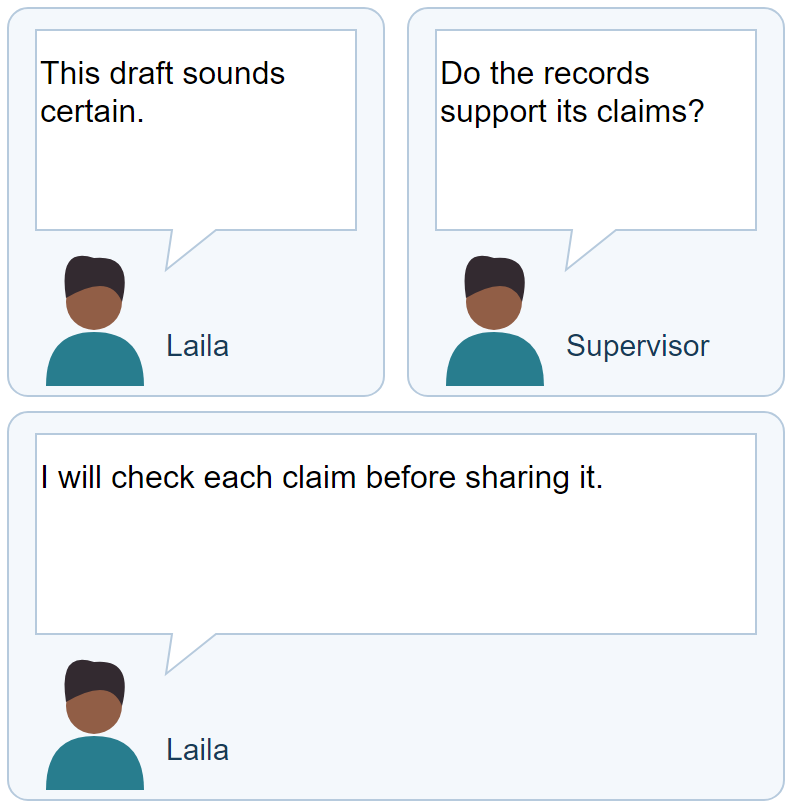

All records in this exercise are invented. Follow Laila's question, inspect the evidence, and check your decision.

## Confidence in wording is not evidence

The course's data → information → knowledge → wisdom pathway connects a result
to context and a defensible action. A fluent draft still needs that pathway.
Use an AI-assisted tool to help draft or organize text only when the task and data
are appropriate; retain human responsibility for checking the evidence and release.

Laila receives this **practice draft**:

1. **All reported cases are laboratory-positive.**
2. **No laboratory follow-up is needed.**
3. **Contaminated water caused this cluster.**

The local records below include pending results and cases without a laboratory match.
A missing result is not a negative result, and these descriptive data do not establish
a cause. Even a numerically correct statement may need contextual review.

Run the next cell to compute the evidence summary. Mark **every unsupported claim**
and choose what should happen before the draft is shared. The supplied draft is the
object of review; you do not need an AI account or to submit any records to a service.


![Course visual: the information value pathway](../../readings/ucsf/assets/slide-previews/unit-1-026.jpg)

*Slide connection: Unit 1, Version 2, slide 26. Use this visual as you compare the source, control, or evidence in the task.*


In [ ]:
# Run once to inspect the data and display the controls.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from IPython.display import display
from html import escape
from collections import Counter
from datetime import date
display(widgets.HTML("""<style>
.course-task-control { height: auto !important; margin-bottom: 0.75rem; gap: 0.25rem; }
.course-task-control > label { width: auto !important; text-align: left; white-space: normal; line-height: 1.4; }
.course-task-control > select, .course-task-control > input { width: 100% !important; min-width: 0; max-width: 100%; flex: 0 0 auto !important; }
</style>"""))

training_data = {'sources': [{'id': 'case', 'grain': 'case', 'fields': ['case_id', 'district', 'onset_date', 'age'], 'access': 'district analyst'}, {'id': 'lab', 'grain': 'case', 'fields': ['case_id', 'specimen_date', 'result'], 'access': 'authorized laboratory extract'}, {'id': 'weekly', 'grain': 'district-week', 'fields': ['district', 'week', 'count'], 'access': 'public summary'}], 'required_fields': ['case_id', 'district', 'onset_date', 'result'], 'cases': [{'case_id': 'C01', 'district': 'Kambia', 'onset_date': '2021-10-18', 'age': 8, 'contact_label': 'Training contact A'}, {'case_id': 'C02', 'district': 'Kambia', 'onset_date': '2021-10-19', 'age': 12, 'contact_label': 'Training contact B'}, {'case_id': 'C03', 'district': 'Kambia', 'onset_date': '2021-10-20', 'age': 4, 'contact_label': 'Training contact C'}, {'case_id': 'C04', 'district': 'Port Loko', 'onset_date': '2021-10-20', 'age': 17, 'contact_label': 'Training contact D'}], 'lab': [{'case_id': 'C01', 'specimen_date': '2021-10-21', 'result': 'positive'}, {'case_id': 'C02', 'specimen_date': '2021-10-22', 'result': 'pending'}], 'role_fields': ['case_id', 'district', 'onset_date', 'age'], 'task_fields': ['case_id', 'district', 'onset_date'], 'release_minimum': 3, 'form': {'required': ['case_id', 'district', 'age'], 'age_min': 0, 'age_max': 120, 'districts': ['Kambia', 'Port Loko']}, 'submissions': [{'case_id': 'T01', 'district': 'Kambia', 'age': 8}, {'case_id': '', 'district': 'Kambia', 'age': 8}, {'case_id': 'T03', 'district': 'Kambia', 'age': 180}, {'case_id': 'T04', 'district': 'Other', 'age': 8}, {'case_id': 'T05', 'district': '', 'age': 8}, {'case_id': 'T06', 'district': 'Kambia', 'age': None}], 'dirty': [{'case_id': 'Q01', 'district': 'Kambia', 'age': 8, 'onset_date': '2021-10-18', 'report_date': '2021-10-19'}, {'case_id': 'Q01', 'district': 'Kambia', 'age': 8, 'onset_date': '2021-10-18', 'report_date': '2021-10-19'}, {'case_id': 'Q02', 'district': '', 'age': 12, 'onset_date': '2021-10-19', 'report_date': '2021-10-20'}, {'case_id': 'Q03', 'district': 'Port Loko', 'age': 180, 'onset_date': '2021-10-20', 'report_date': '2021-10-21'}, {'case_id': 'Q04', 'district': 'Kambia', 'age': 4, 'onset_date': '2021-10-18', 'report_date': '2021-10-25'}], 'timely_days': 2, 'verified_corrections': [{'case_id': 'Q02', 'field': 'district', 'value': 'Port Loko', 'evidence': 'Training register review: district confirmed'}, {'case_id': 'Q03', 'field': 'age', 'value': 18, 'evidence': 'Training register review: age confirmed as 18 years'}], 'verified_duplicate': {'case_id': 'Q01', 'evidence': 'Training source review: these identical rows are the same report'}}

def show_table(rows):
    if not rows:
        display(widgets.HTML("<p>No rows selected.</p>"))
        return
    names = list(rows[0])
    header = "".join("<th>" + escape(str(name)) + "</th>" for name in names)
    body = "".join("<tr>" + "".join("<td>" + escape(str(row.get(name, ""))) + "</td>" for name in names) + "</tr>" for row in rows)
    display(widgets.HTML('<div style="overflow-x:auto"><table><thead><tr>' + header + '</tr></thead><tbody>' + body + '</tbody></table></div>'))


def audit_quality(data):
    rows = data["dirty"]
    ids = Counter(row["case_id"] for row in rows)
    return {"missing": sum(not row["district"] for row in rows),
            "duplicates": sum(count - 1 for count in ids.values()),
            "invalid": sum(not data["form"]["age_min"] <= row["age"] <= data["form"]["age_max"] for row in rows),
            "late": sum((date.fromisoformat(row["report_date"]) - date.fromisoformat(row["onset_date"])).days > data["timely_days"] for row in rows)}


def expected_answers(unit, data):
    """Recompute training expectations from source coverage and explicit rules."""
    if unit == 4:
        # Each selected source must add a required field; the aggregate lacks case IDs.
        required = set(data["required_fields"])
        selected = [s["id"] for s in data["sources"] if s["grain"] == "case" and required & set(s["fields"])]
        return {"sources": selected, "grain": "case"}
    if unit == 5:
        counts = Counter(row["district"] for row in data["cases"])
        return {"fields": sorted(set(data["task_fields"]) & set(data["role_fields"])),
                "suppress": sorted(k for k, v in counts.items() if v < data["release_minimum"])}
    if unit == 6:
        total = len(data["cases"])
        positive = sum(row["result"] == "positive" for row in data["lab"])
        # Claims 1 and 2 are numeric, claim 3 asserts causation without supporting evidence.
        claimed = {"all_positive": positive == total, "no_followup": all(row["result"] != "pending" for row in data["lab"])
                   and len(data["lab"]) == total, "water_caused": False}
        return {"claims": sorted(k for k, supported in claimed.items() if not supported), "review": "human_review"}
    if unit == 7:
        return {"required": data["form"]["required"], "age_max": data["form"]["age_max"],
                "district_control": "list"}
    if unit == 8:
        rows = data["dirty"]
        ids = Counter(row["case_id"] for row in rows)
        return {"missing": sum(not row["district"] for row in rows),
                "duplicates": sum(v - 1 for v in ids.values()),
                "invalid": sum(not data["form"]["age_min"] <= row["age"] <= data["form"]["age_max"] for row in rows),
                "late": sum((date.fromisoformat(row["report_date"]) - date.fromisoformat(row["onset_date"])).days > data["timely_days"] for row in rows),
                "repair": "verify_and_log"}
    raise ValueError(unit)


def evaluate_answer(unit, response, data):
    expected = expected_answers(unit, data)
    if not isinstance(response, dict) or any(response.get(k) is None or response.get(k) == [] for k in expected):
        return "incomplete"
    for key, value in expected.items():
        actual = response.get(key)
        if isinstance(value, list):
            if not isinstance(actual, (list, tuple)) or sorted(actual) != sorted(value):
                return "incorrect"
        elif actual != value:
            return "incorrect"
    return "correct"


def build_artifact(unit, response, data):
    """The learner's choices drive a real local transformation, including bad choices."""
    if unit == 4:
        selected = response["sources"]
        fields = set().union(*(set(s["fields"]) for s in data["sources"] if s["id"] in selected))
        print("Required fields not covered:", sorted(set(data["required_fields"]) - fields))
        if "case" in selected:
            lab = {row["case_id"]: row for row in data["lab"]} if "lab" in selected else {}
            return [{"case_id": row["case_id"], "district": row["district"], "onset_date": row["onset_date"],
                     "result": lab.get(row["case_id"], {}).get("result", "unknown")} for row in data["cases"]]
        return [{"district": key, "count": value} for key, value in Counter(row["district"] for row in data["cases"]).items()] if "weekly" in selected else []
    if unit == 5:
        allowed = set(response["fields"]) & set(data["role_fields"])
        denied = set(response["fields"]) - set(data["role_fields"])
        if denied:
            print("Role access denied for:", sorted(denied))
        internal = [{key: row[key] for key in response["fields"] if key in row and key in allowed} for row in data["cases"]] if allowed else []
        public = [{"district": key, "public_count": "withheld" if key in response["suppress"] else count}
                  for key, count in Counter(row["district"] for row in data["cases"]).items()]
        return {"Internal extract (invented records)": internal, "Public summary": public}
    if unit == 6:
        positive = sum(row["result"] == "positive" for row in data["lab"])
        pending = sum(row["result"] == "pending" for row in data["lab"])
        unmatched = len({row["case_id"] for row in data["cases"]} - {row["case_id"] for row in data["lab"]})
        return [{"measure": "Reported cases", "count": len(data["cases"])},
                {"measure": "Positive laboratory results", "count": positive},
                {"measure": "Pending laboratory results", "count": pending},
                {"measure": "Cases without a laboratory match", "count": unmatched}]
    if unit == 7:
        tested = []
        for i, row in enumerate(data["submissions"], 1):
            errors = [key + " required" for key in response["required"] if row.get(key) in (None, "")]
            age = row.get("age")
            if age not in (None, "") and (type(age) is not int or not data["form"]["age_min"] <= age <= response["age_max"]):
                errors.append("age must be whole years within range")
            if response["district_control"] == "list" and row.get("district") not in (None, "") and row["district"] not in data["form"]["districts"]:
                errors.append("district not recognized")
            tested.append({"submission": i, "accepted": not errors, "errors": "; ".join(errors)})
        return tested
    if unit == 8:
        actual = audit_quality(data)
        print("Computed audit:", actual)
        if response["repair"] != "verify_and_log":
            print("No changes applied: choose source verification with originals and a correction log.")
            return [dict(row) for row in data["dirty"]]
        cleaned, ledger, seen = [], [], {}
        for source in data["dirty"]:
            row = dict(source)
            if seen.get(row["case_id"]) == source and row["case_id"] == data["verified_duplicate"]["case_id"]:
                ledger.append({"case_id": row["case_id"], "field": "duplicate row", "before": dict(row),
                               "after": "earlier identical report retained", "evidence": data["verified_duplicate"]["evidence"]})
                continue
            seen[row["case_id"]] = dict(source)
            for change in data["verified_corrections"]:
                if change["case_id"] == row["case_id"]:
                    ledger.append({"case_id": row["case_id"], "field": change["field"], "before": row[change["field"]],
                                   "after": change["value"], "evidence": change["evidence"]})
                    row[change["field"]] = change["value"]
            cleaned.append(row)
        print("Audit after verified repairs:", audit_quality({**data, "dirty": cleaned}))
        return {"Verified correction log": ledger, "Cleaned copy": cleaned}
    return []

unit06_response = None
controls = {}
display(widgets.HTML('<p>For multiple choices, hold Ctrl (Command on Mac) while selecting items.</p>'))
show_table(build_artifact(6, {}, training_data))
controls['claims'] = widgets.SelectMultiple(description='Unsupported claims', options=[('All cases laboratory-positive', 'all_positive'), ('No follow-up needed', 'no_followup'), ('Water caused the cluster', 'water_caused')], value=(), rows=3, style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['claims'].add_class('course-task-control')
display(controls['claims'])
controls['review'] = widgets.Dropdown(description='Before sharing', options=[('Select an answer', None), ('Human evidence and disclosure review', 'human_review'), ('Share the draft automatically', 'auto_release')], value=None, style={'description_width': 'initial'}, layout=widgets.Layout(width='100%', flex_flow='column', align_items='stretch'))
controls['review'].add_class('course-task-control')
display(controls['review'])


## Check my work

Run the next cell after making your choices. Incomplete and incorrect attempts remain in your learning record. You can revise your choices and try again.

In [ ]:
# Check my work: run after making your choices above. Revise and run again to retry.
unit06_response = {key: (list(control.value) if isinstance(control, widgets.SelectMultiple)
                       else None if isinstance(control, widgets.BoundedIntText) and control.value < 0
                       else control.value) for key, control in controls.items()}
result = evaluate_answer(6, unit06_response, training_data)
if result == "incomplete":
    print("Incomplete: answer every field, then check again.")
else:
    artifact = build_artifact(6, unit06_response, training_data)
    if isinstance(artifact, dict):
        for title, rows in artifact.items():
            print(title)
            show_table(rows)
    else:
        show_table(artifact)
    print("Correct: your result follows the stated evidence and training rules." if result == "correct"
          else "Not yet correct: compare the artifact with the task and rules. Revise your choices and retry; the Learning panel offers hints.")


## Reflect on the decision

Run the next cell to write your reflections. Select **Record** to save them with your learner record in this browser. Reflections are unscored.

In [ ]:
# Run this cell to write and record your reflections.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from html import escape
from IPython.display import display
from comm import create_comm

def _reflection_section(section, prompts):
    fields = []
    for number, prompt in enumerate(prompts, 1):
        field = widgets.Textarea(placeholder="Write your reflection here", rows=5,
                                 layout=widgets.Layout(width="100%"))
        fields.append(field)
        display(widgets.VBox([
            widgets.HTML(value=f"<strong>{number}. {escape(prompt)}</strong>"), field
        ], layout=widgets.Layout(width="100%", padding="0.5rem", margin="0 0 0.5rem 0")))
    button = widgets.Button(description="Record", button_style="info", disabled=True)
    status = widgets.HTML(value="Connecting to your browser learner record...")
    channel = create_comm(target_name="al.reflections", data={"section": section})
    def receive(message):
        data = message["content"]["data"]
        if "entries" in data:
            saved = {entry["prompt"]: entry["answer"] for entry in data["entries"]}
            for prompt, field in zip(prompts, fields):
                field.value = saved.get(prompt, "")
            status.value = "Recorded reflections restored." if saved else "Select Record to save in this browser."
        elif data.get("saved"):
            status.value = "Recorded in this browser. Your reflections are unscored."
        else:
            status.value = escape(data.get("error", "Could not record. Please try again."))
        button.disabled = False
    channel.on_msg(receive)
    def record(_):
        button.disabled = True
        status.value = "Recording..."
        channel.send({"entries": [{"prompt": prompt, "answer": field.value}
                                  for prompt, field in zip(prompts, fields)]})
    def edited(_):
        status.value = "Changes not recorded. Select Record to save."
    for field in fields:
        field.observe(edited, names="value")
    button.on_click(record)
    display(button, status)

_reflection_section('exercise:u06-ai-use-and-review', ['Rewrite one unsupported claim using only the available evidence and its limitations.', 'What data and release conditions would you check before using an AI-assisted tool for this task?'])


## Continue Laila's case

[Next notebook](u07-n01-form-design-validation.ipynb) · [Course start](u00-n00-start-here.ipynb)

Use the **Learning** panel to see what this attempt recorded and what it recommends. Your learning record keeps attempts and hints used.

## References

- FETP Version 2 Unit 1, slides 26–27 (information value); Unit 7, interpretation and information bias. AI review is an authored practice scenario.
- [Unit 1 course slides (local PDF)](../../readings/ucsf/assets/unit-1-version-2-slides.pdf).
